# LQR tracking: following a reference trajectory

This notebook uses the double integrator from the
[previous example](lqr_integrator.ipynb), but now the state should follow a time-varying target
$x^\star_t$ rather than return to the origin:

$$
J = \tfrac12 (x_T - x^\star_T)^\top Q_f (x_T - x^\star_T)
  + \sum_{t=0}^{T-1} \tfrac12 (x_t - x^\star_t)^\top Q (x_t - x^\star_t) + \tfrac12 u_t^\top R u_t .
$$

**From tracking to standard LQR.** Expanding the square gives
$\tfrac12 x^\top Q x - (Q x^\star)^\top x + \text{const}$. Tracking is therefore a standard LQR
with linear cost terms

$$
q_t = -Q x^\star_t, \qquad q_f = -Q_f x^\star_T .
$$

The constant does not change the optimal trajectory.

In [1]:
from functools import partial

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

from diffilqrax.lqr import solve_lqr, kkt
from diffilqrax.typs import LQR, LQRParams, ModelDims

jax.config.update("jax_enable_x64", True)

## Target trajectory

The position should follow a sine wave, and the velocity should follow the matching cosine (the
time derivative of the position target). With these targets the reference is dynamically
consistent, so the controller can track it closely.

In [2]:
dims = ModelDims(n=2, m=1, horizon=200, dt=0.05)
T, n, m = dims.horizon, dims.n, dims.m
time = jnp.arange(T + 1) * dims.dt

omega = 2 * jnp.pi / 5.0  # period of 5 time units
x_target = jnp.stack([jnp.sin(omega * time), omega * jnp.cos(omega * time)], axis=-1)  # (T+1, n)

## Setting up the LQR

Only the linear terms differ from the regulation problem. The position error is weighted more than
the velocity error, and the terminal weight $Q_f$ is set equal to $Q$.

In [3]:
A = jnp.array([[1.0, dims.dt], [0.0, 1.0]])
B = jnp.array([[0.5 * dims.dt**2], [dims.dt]])
Q = jnp.diag(jnp.array([100.0, 1.0]))
R = 0.1 * jnp.eye(m)
Qf = Q

span_mat = partial(jnp.tile, reps=(T, 1, 1))
span_vec = partial(jnp.tile, reps=(T, 1))

lqr = LQR(
    A=span_mat(A),
    B=span_mat(B),
    a=span_vec(jnp.zeros(n)),
    Q=span_mat(Q),
    q=-(x_target[:-1] @ Q.T),  # q_t = -Q x*_t
    R=span_mat(R),
    r=span_vec(jnp.zeros(m)),
    S=span_mat(jnp.zeros((n, m))),
    Qf=Qf,
    qf=-Qf @ x_target[-1],     # q_f = -Q_f x*_T
)
params = LQRParams(x0=jnp.array([-1.0, 0.0]), lqr=lqr)  # start away from the target

In [4]:
Xs, Us, lambdas = solve_lqr(params)
dLdX, dLdU, dLdLambda = kkt(params, Xs, Us, lambdas)
print(f"KKT residuals: {max(jnp.abs(r).max() for r in (dLdX, dLdU, dLdLambda)):.2e}")

KKT residuals: 8.03e-13


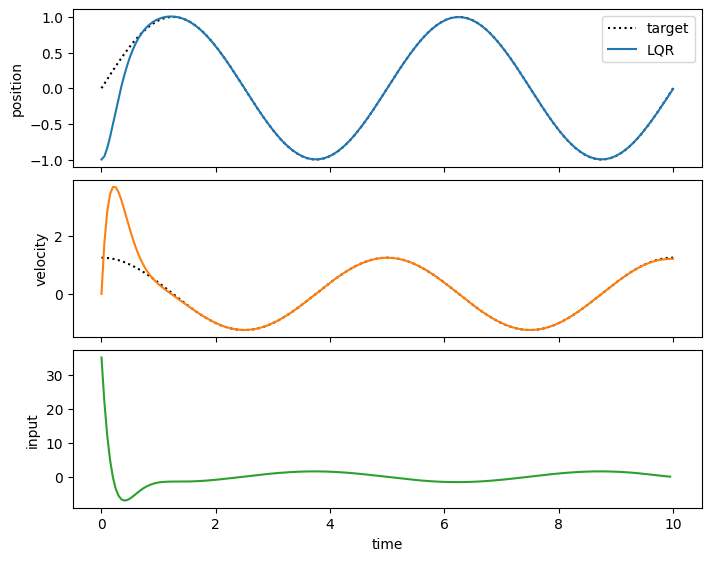

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(7, 5.5), sharex=True, layout="constrained")
for i, label in enumerate(["position", "velocity"]):
    axes[i].plot(time, x_target[:, i], "k:", label="target")
    axes[i].plot(time, Xs[:, i], c=f"C{i}", label="LQR")
    axes[i].set_ylabel(label)
axes[0].legend(loc="upper right")
axes[2].plot(time[:-1], Us, c="C2")
axes[2].set(ylabel="input", xlabel="time");

The controller first closes the gap from $x_0 = (-1, 0)$ to the target. After that, the input is
the acceleration the reference needs, $-\omega^2 \sin(\omega t)$.

## How to adapt

- **Any reference:** set `x_target` to any array of shape `(T+1, n)`. If the reference is not
  dynamically feasible, the controller trades tracking error against effort through `Q` and `R`.
- **Tracking only part of the state:** put zeros in the diagonal of `Q` for components you do not
  care about. Their entries in `q` then vanish automatically.
- **Input references:** to track a nominal input $u^\star_t$, set `r = -(u_target @ R.T)` in the
  same way.
- **Time-varying weights:** build `Q` with shape `(T, n, n)`. For example, weight later times more
  heavily to allow a transient at the start.